In [ ]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, transforms

In [2]:
# 1. Load MNIST Dataset using torchvision

train_dataset = datasets.MNIST(

    root="./data", train=True, download=True, transform=transforms.ToTensor()

)

test_dataset = datasets.MNIST(

    root="./data", train=False, download=True, transform=transforms.ToTensor()

)

100.0%
100.0%
100.0%
100.0%


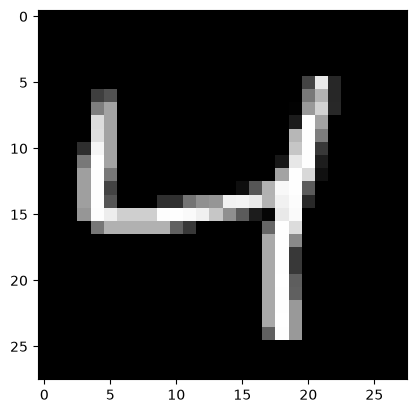

In [3]:
# Visualize an image (equivalent to plt.imshow(X_train[2]))

plt.imshow(train_dataset[2][0].squeeze(), cmap="gray")

plt.show()

In [4]:
# Create DataLoaders with a train/validation split (80/20)

train_size = int(0.8 * len(train_dataset))

val_size = len(train_dataset) - train_size

train_subset, val_subset = torch.utils.data.random_split(

    train_dataset, [train_size, val_size]

)



train_loader = DataLoader(train_subset, batch_size=32, shuffle=True)

val_loader = DataLoader(val_subset, batch_size=32, shuffle=False)

test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [5]:
# 2. Define Sequential Neural Network Model

class MNISTModel(nn.Module):



    def __init__(self):

        super(MNISTModel, self).__init__()

        self.model = nn.Sequential(

            nn.Flatten(),

            nn.Linear(28 * 28, 128),

            nn.ReLU(),

            nn.Linear(128, 32),

            nn.ReLU(),

            nn.Linear(32, 10),

        )



    def forward(self, x):

        return self.model(x)





model = MNISTModel()

print(model)

MNISTModel(
  (model): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=10, bias=True)
  )
)


In [6]:
# 3. Define Loss Function and Optimizer

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(model.parameters())



In [8]:
# 4. Training Loop (25 Epochs)

epochs = 25

history = {"loss": [], "val_loss": [], "accuracy": [], "val_accuracy": []}



for epoch in range(epochs):

    # --- Training Phase ---

    model.train()

    running_loss = 0.0

    correct = 0

    total = 0



    for inputs, labels in train_loader:

        optimizer.zero_grad()

        outputs = model(inputs)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()



        running_loss += loss.item() * inputs.size(0)

        _, predicted = outputs.max(1)

        total += labels.size(0)

        correct += predicted.eq(labels).sum().item()



    train_loss = running_loss / len(train_loader.dataset)

    train_acc = correct / total



    # --- Validation Phase ---

    model.eval()

    val_running_loss = 0.0

    val_correct = 0

    val_total = 0



    with torch.no_grad():

        for inputs, labels in val_loader:

            outputs = model(inputs)

            loss = criterion(outputs, labels)



            val_running_loss += loss.item() * inputs.size(0)

            _, predicted = outputs.max(1)

            val_total += labels.size(0)

            val_correct += predicted.eq(labels).sum().item()



    val_loss = val_running_loss / len(val_loader.dataset)

    val_acc = val_correct / val_total



    history["loss"].append(train_loss)

    history["val_loss"].append(val_loss)

    history["accuracy"].append(train_acc)

    history["val_accuracy"].append(val_acc)



    print(

        f"Epoch {epoch+1}/{epochs} - loss: {train_loss:.4f} - accuracy: {train_acc:.4f} - val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f}"

    )



Epoch 1/25 - loss: 0.0099 - accuracy: 0.9968 - val_loss: 0.1443 - val_accuracy: 0.9756
Epoch 2/25 - loss: 0.0085 - accuracy: 0.9971 - val_loss: 0.1658 - val_accuracy: 0.9733
Epoch 3/25 - loss: 0.0090 - accuracy: 0.9973 - val_loss: 0.1480 - val_accuracy: 0.9766
Epoch 4/25 - loss: 0.0077 - accuracy: 0.9973 - val_loss: 0.1615 - val_accuracy: 0.9728
Epoch 5/25 - loss: 0.0104 - accuracy: 0.9966 - val_loss: 0.1506 - val_accuracy: 0.9750
Epoch 6/25 - loss: 0.0077 - accuracy: 0.9973 - val_loss: 0.1705 - val_accuracy: 0.9742
Epoch 7/25 - loss: 0.0075 - accuracy: 0.9974 - val_loss: 0.2001 - val_accuracy: 0.9709
Epoch 8/25 - loss: 0.0073 - accuracy: 0.9974 - val_loss: 0.1641 - val_accuracy: 0.9765
Epoch 9/25 - loss: 0.0086 - accuracy: 0.9971 - val_loss: 0.2225 - val_accuracy: 0.9705
Epoch 10/25 - loss: 0.0036 - accuracy: 0.9989 - val_loss: 0.1805 - val_accuracy: 0.9758
Epoch 11/25 - loss: 0.0103 - accuracy: 0.9969 - val_loss: 0.1877 - val_accuracy: 0.9750
Epoch 12/25 - loss: 0.0051 - accuracy: 0.

In [9]:
# 5. Evaluate Accuracy on Test Set (Replaces sklearn accuracy_score)

model.eval()

all_preds = []

all_labels = []



with torch.no_grad():

    for inputs, labels in test_loader:

        outputs = model(inputs)

        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())

        all_labels.extend(labels.cpu().numpy())



test_accuracy = sum(p == l for p, l in zip(all_preds, all_labels)) / len(

    all_labels

)

print(f"\nTest Accuracy: {test_accuracy:.4f}")




Test Accuracy: 0.9765


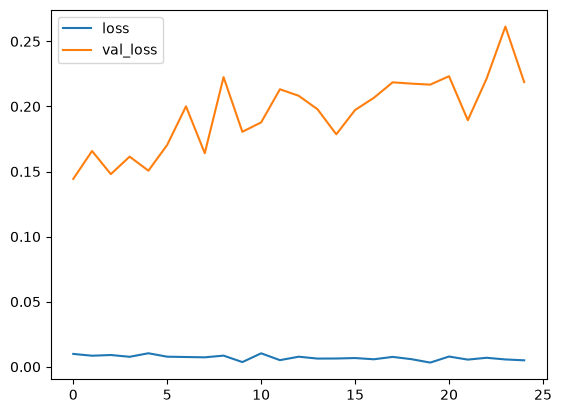

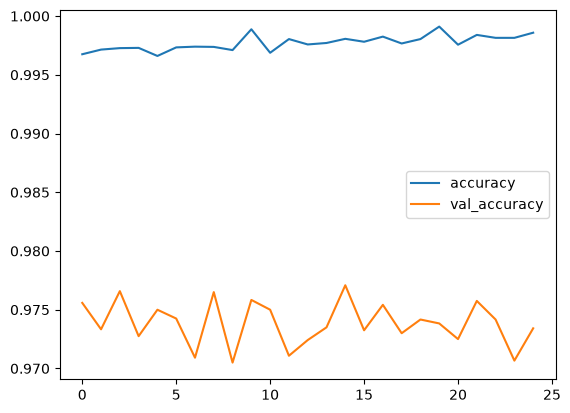

In [10]:
# 6. Plotting Training History

plt.figure()

plt.plot(history["loss"], label="loss")

plt.plot(history["val_loss"], label="val_loss")

plt.legend()

plt.show()



plt.figure()

plt.plot(history["accuracy"], label="accuracy")

plt.plot(history["val_accuracy"], label="val_accuracy")

plt.legend()

plt.show() 